# 01 · Data Understanding, Cleaning and Exploratory Data Analysis
**Project:** Customer Churn Prediction and Retention Analysis Using Machine Learning
**Course:** CSE3141 Predictive Analytics · Manipal University Jaipur

**Dataset:** IBM *Telco Customer Churn* sample data (7,043 customers, 21 columns), saved as
`data/raw/Telco-Customer-Churn.csv`.

**Target:** `Churn` - whether the customer left within the last month.

This notebook covers syllabus parts **A (data understanding & cleaning)** and **B (EDA)**.
Reusable logic lives in `src/data_preprocessing.py` and `src/eda.py`; this notebook shows each step.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## A1. Load and inspect the raw data

In [2]:
from src.data_preprocessing import load_raw_data, data_quality_report, clean_data, iqr_outliers

raw = load_raw_data()
print("Shape:", raw.shape)
raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Observation:** `TotalCharges` is stored as `object` (text) although it is a monetary amount.
`SeniorCitizen` is an integer 0/1 while all other yes/no columns are text. These are fixed below.

## A2. Missing values, blank strings and duplicates

In [4]:
print("NaN values per column (non-zero only):")
print(raw.isna().sum()[raw.isna().sum() > 0])
print()
tc_numeric = pd.to_numeric(raw["TotalCharges"], errors="coerce")
print("TotalCharges values that are not numbers:", tc_numeric.isna().sum())
print("Their raw value:", raw.loc[tc_numeric.isna(), "TotalCharges"].unique())
print("Tenure of those customers:", raw.loc[tc_numeric.isna(), "tenure"].unique())
print()
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate customer IDs:", raw["customerID"].duplicated().sum())
print("Duplicate rows if customerID is ignored:", raw.drop(columns="customerID").duplicated().sum())

NaN values per column (non-zero only):
Series([], dtype: int64)

TotalCharges values that are not numbers: 11
Their raw value: [' ']
Tenure of those customers: [0]

Duplicate rows: 0
Duplicate customer IDs: 0
Duplicate rows if customerID is ignored: 22


**Interpretation**
- `isna()` reports no missing values, but this is misleading: 11 `TotalCharges` cells contain a blank
  string `' '`. Hidden missing values like this are common in real data.
- All 11 have `tenure = 0`: they joined this month and have not been billed yet, so the logically
  correct value is **0**, not the mean/median. (Mean imputation would invent a bill they never paid.)
- No duplicate rows or customer IDs. Some customers share identical attributes once the ID is removed,
  but they are different customers with identical profiles (very plausible with mostly categorical
  columns), so they are **kept**.

## A3. Inconsistent values

In [5]:
for col in raw.select_dtypes("object").columns.drop(["customerID", "TotalCharges"]):
    print(f"{col:17s} {sorted(raw[col].unique())}")

gender            ['Female', 'Male']
Partner           ['No', 'Yes']
Dependents        ['No', 'Yes']
PhoneService      ['No', 'Yes']
MultipleLines     ['No', 'No phone service', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
OnlineSecurity    ['No', 'No internet service', 'Yes']
OnlineBackup      ['No', 'No internet service', 'Yes']
DeviceProtection  ['No', 'No internet service', 'Yes']
TechSupport       ['No', 'No internet service', 'Yes']
StreamingTV       ['No', 'No internet service', 'Yes']
StreamingMovies   ['No', 'No internet service', 'Yes']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['No', 'Yes']
PaymentMethod     ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn             ['No', 'Yes']


**Interpretation:** `"No internet service"` appears in six add-on columns and `"No phone service"`
in `MultipleLines`. That information is already in `InternetService` and `PhoneService`, so after
one-hot encoding it would create perfectly collinear (duplicate) columns. They are mapped to `"No"`
(meaning "does not have this add-on"). `SeniorCitizen` 0/1 is recoded to No/Yes for consistency.

## A4. Apply the cleaning rules

In [6]:
df = clean_data(raw)
print(df.dtypes.value_counts())
print("Remaining missing values:", df.isna().sum().sum())
print("Target distribution:", df["Churn"].value_counts().to_dict())
df.head()

object     17
int64       2
float64     2
Name: count, dtype: int64
Remaining missing values: 0
Target distribution: {0: 5174, 1: 1869}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


These cleaning steps are **deterministic row-level rules** (they do not learn any statistic from the
data), so applying them before the train/test split cannot leak test information. Scaling and
encoding, which *do* learn from data, are done later inside a scikit-learn `Pipeline`.

## A5. Outlier detection with IQR and box plots

In [7]:
iqr_outliers(df).round(2)

,feature,Q1,Q3,IQR,lower_fence,upper_fence,min,max,n_outliers
0,tenure,9.00,55.00,46.00,-60.00,124.00,0.00,72.00,0
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,18.25,118.75,0
2,TotalCharges,398.55,3786.60,3388.05,-4683.52,8868.67,0.00,8684.80,0


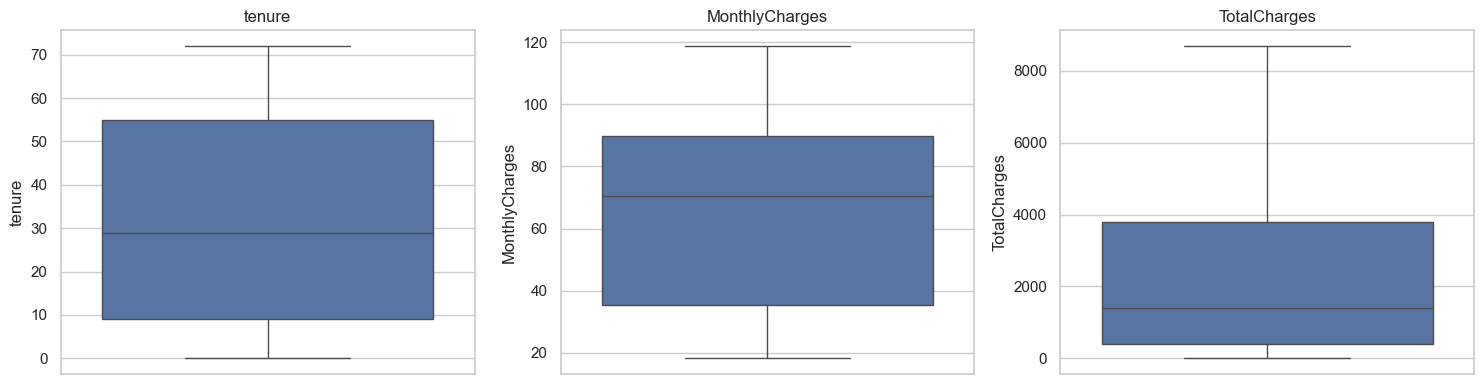

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, config.NUMERIC_FEATURES):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Interpretation:** Using Tukey's rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR), **no numeric
feature has outliers**. `TotalCharges` is right-skewed (long tail of long-tenure, high-spend customers),
but those values are genuine, so nothing is removed or capped. Tree models are unaffected by skew;
for Logistic Regression/LDA we standardise the features.

## B1. Descriptive statistics

In [9]:
from src.eda import descriptive_stats, churn_rate_by, chi_square_tests, numeric_group_tests
descriptive_stats(df).round(2)

,count,mean,median,mode,variance,std,min,max,skewness
feature,,,,,,,,,
tenure,7043,32.37,29.00,1.00,603.17,24.56,0.00,72.00,0.24
MonthlyCharges,7043,64.76,70.35,20.05,905.41,30.09,18.25,118.75,-0.22
TotalCharges,7043,2279.73,1394.55,0.00,5138357.17,2266.79,0.00,8684.80,0.96


- **tenure:** mean ≈ 32 months, median 29, but the *mode* is 1 month - many customers are brand new.
- **MonthlyCharges:** mean (≈ 64.8) < median (70.35) → slightly left-skewed; mode ≈ 20 (basic phone-only plans).
- **TotalCharges:** mean (≈ 2,280) far above median (≈ 1,395) → strongly right-skewed (skewness ≈ 0.96).

In [10]:
df[config.CATEGORICAL_FEATURES].describe().T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,2,No,4072
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,2,No,5024
OnlineBackup,7043,2,No,4614
DeviceProtection,7043,2,No,4621


## B2. Churn distribution (class balance)

In [11]:
counts = df["Churn"].value_counts().rename({0: "No", 1: "Yes"})
print(counts, "\n")
print(f"Churn rate: {df['Churn'].mean():.2%}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
counts.plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0, title="Churn count")
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#4C72B0", "#DD8452"])
axes[1].set_title("Churn share"); plt.show()

Churn
No     5174
Yes    1869
Name: count, dtype: int64 

Churn rate: 26.54%


/var/folders/j_/jjwfvh_97flg6zjpgn1_6mcw0000gn/T/ipykernel_15281/682982643.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  axes[1].set_title("Churn share"); plt.show()


**Interpretation:** about **26.5 %** of customers churned. The classes are **imbalanced** (≈ 3:1).
A model that always predicts "No churn" would already be ≈ 73.5 % accurate while being useless, so
accuracy alone is not a suitable metric. We will use recall, precision, F1 and ROC-AUC, and handle
the imbalance with class weights.

## B3. Churn by contract, tenure and monthly charges

In [12]:
churn_rate_by(df, "Contract").round(2)

,customers,churned,churn_rate_%
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


In [13]:
from src.data_preprocessing import tenure_group
df["TenureGroup"] = tenure_group(df["tenure"])
df["MonthlyChargeBand"] = pd.qcut(df["MonthlyCharges"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
display(churn_rate_by(df, "TenureGroup").sort_index().round(2))
display(churn_rate_by(df, "MonthlyChargeBand").sort_index().round(2))

,customers,churned,churn_rate_%
TenureGroup,,,
0-12 m,2186,1037,47.44
13-24 m,1024,294,28.71
25-48 m,1594,325,20.39
49-72 m,2239,213,9.51


,customers,churned,churn_rate_%
MonthlyChargeBand,,,
Q1 (lowest),1762,198,11.24
Q2,1766,434,24.58
Q3,1757,659,37.51
Q4 (highest),1758,578,32.88


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["Contract", "TenureGroup", "MonthlyChargeBand"]):
    r = churn_rate_by(df, col).sort_index()
    sns.barplot(x=r.index.astype(str), y=r["churn_rate_%"], ax=ax, color="#DD8452")
    ax.axhline(100 * df["Churn"].mean(), ls="--", c="grey")
    ax.set(title=f"Churn rate by {col}", ylabel="Churn rate (%)", xlabel="")
plt.tight_layout(); plt.show()

/var/folders/j_/jjwfvh_97flg6zjpgn1_6mcw0000gn/T/ipykernel_15281/3653701475.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


**Interpretation**
- **Contract** is the strongest single pattern: month-to-month ≈ 42.7 % churn vs one-year ≈ 11.3 % and two-year ≈ 2.8 %.
- **Tenure:** churn falls steadily with tenure - ≈ 47 % in the first year vs ≈ 9.5 % after four years.
- **Monthly charges:** the lowest-charge quartile churns least (≈ 11 %); the middle-upper quartiles churn most.
  The relationship is not perfectly monotonic (Q3 > Q4).

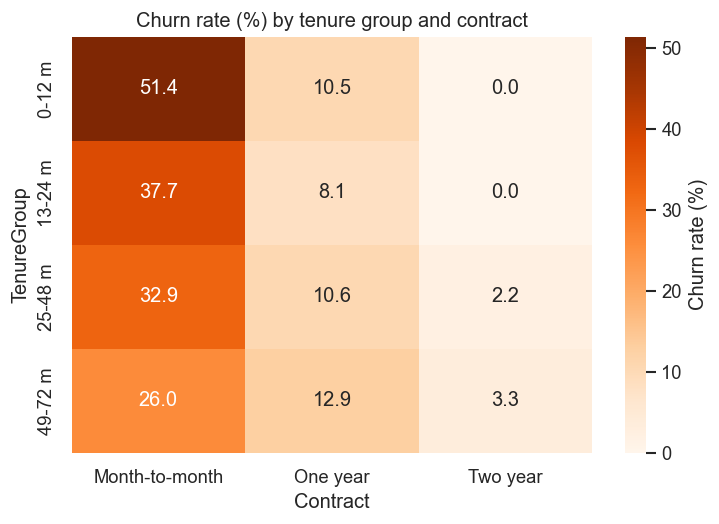

In [15]:
display(Image(str(config.FIGURES_DIR / "eda_tenure_contract_heatmap.png")))

Even within the same tenure band, month-to-month customers churn far more than contract customers,
so contract type is associated with churn beyond what tenure alone explains.

## B4. Histograms and scatter plot

In [16]:
d = df.assign(ChurnLabel=df["Churn"].map({0: "No", 1: "Yes"}))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, config.NUMERIC_FEATURES):
    sns.histplot(data=d, x=col, hue="ChurnLabel", bins=30, stat="density", common_norm=False, kde=True, ax=ax)
plt.tight_layout(); plt.show()

/var/folders/j_/jjwfvh_97flg6zjpgn1_6mcw0000gn/T/ipykernel_15281/2638477071.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=d, x="tenure", y="MonthlyCharges", hue="ChurnLabel", alpha=0.4, s=12)
plt.title("Tenure vs monthly charges"); plt.show()
numeric_group_tests(df).round(4)

/var/folders/j_/jjwfvh_97flg6zjpgn1_6mcw0000gn/T/ipykernel_15281/1345792991.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.title("Tenure vs monthly charges"); plt.show()


,feature,mean_no_churn,mean_churn,median_no_churn,median_churn,mann_whitney_p
0,tenure,37.5700,17.9791,38.000,10.00,0.0
1,MonthlyCharges,61.2651,74.4413,64.425,79.65,0.0
2,TotalCharges,2549.9114,1531.7961,1679.525,703.55,0.0


**Interpretation:** churners cluster at **low tenure and high monthly charges** (top-left of the scatter).
Median tenure is 10 months for churners vs 38 for non-churners. The Mann-Whitney U test (chosen because
the distributions are not normal) gives p-values far below 0.05 for all three numeric features.

## B5. Service and demographic features

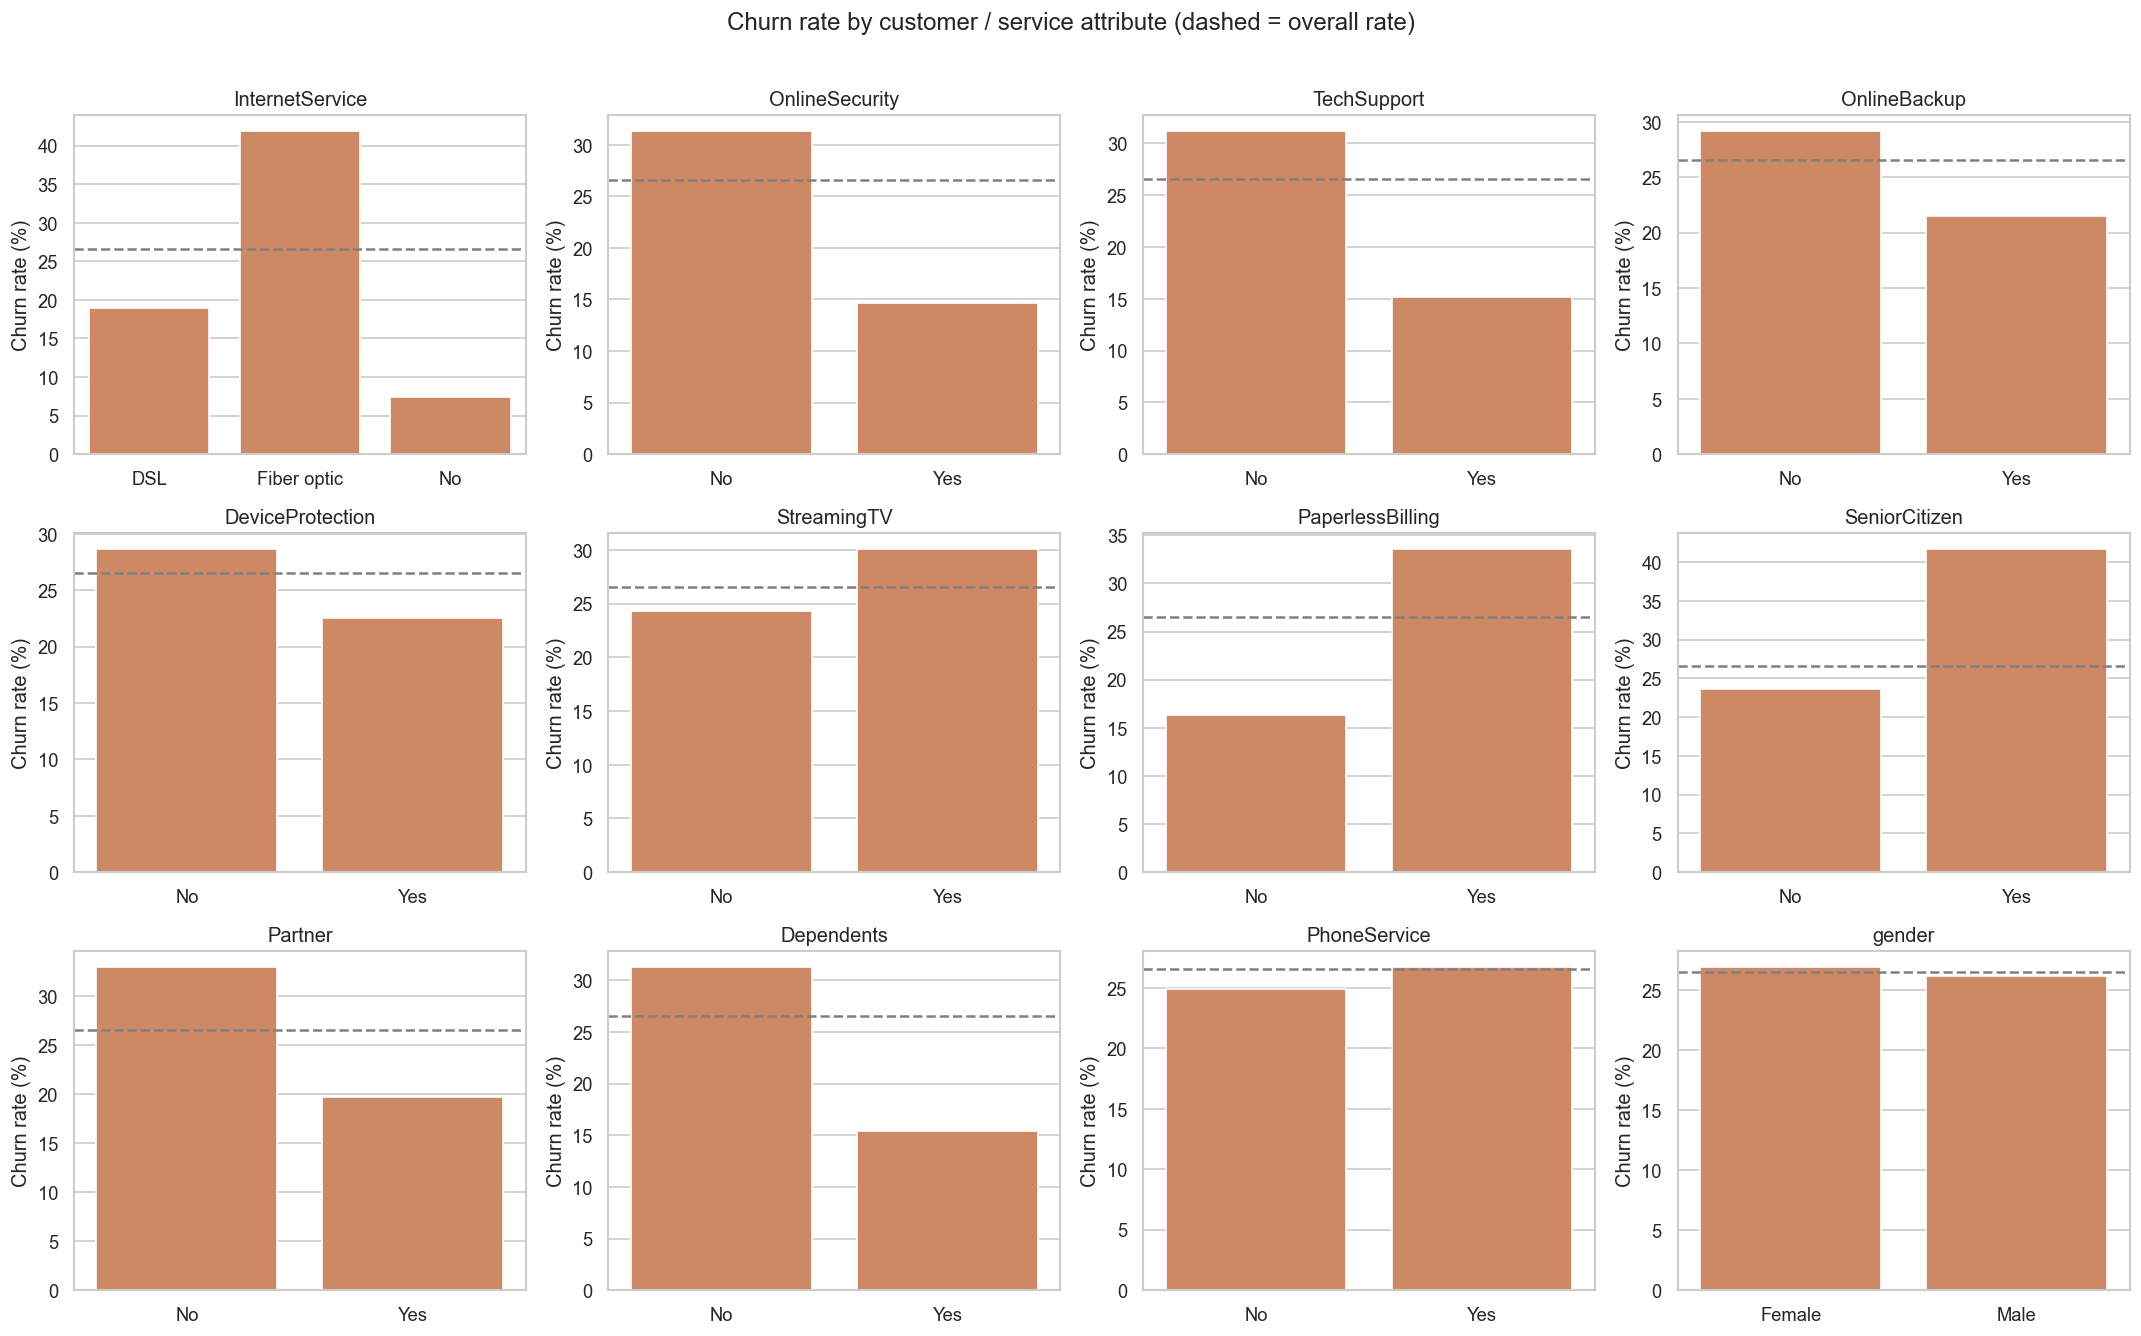

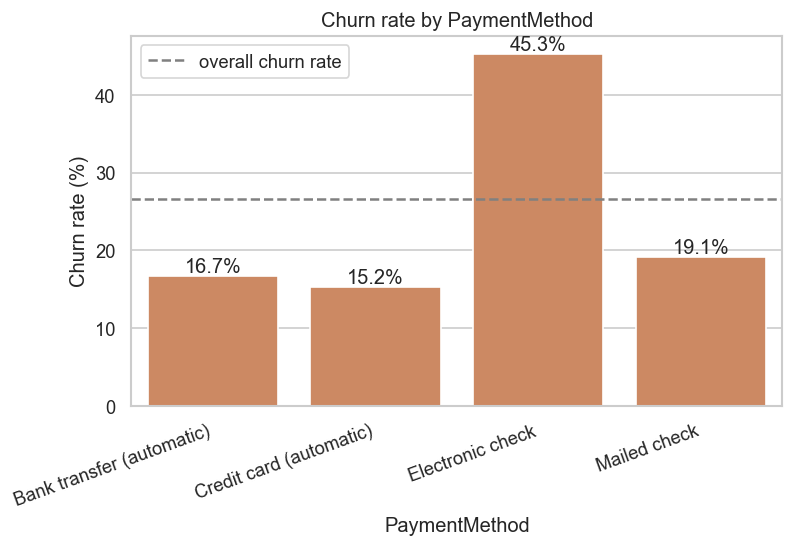

In [18]:
display(Image(str(config.FIGURES_DIR / "eda_service_features.png")))
display(Image(str(config.FIGURES_DIR / "eda_churn_by_payment.png")))

In [19]:
chi_square_tests(df).round(4)

,feature,chi2,dof,p_value,cramers_v
0,Contract,1184.5966,2,0.0000,0.4101
1,InternetService,732.3096,2,0.0000,0.3225
2,PaymentMethod,648.1423,3,0.0000,0.3034
3,PaperlessBilling,258.2776,1,0.0000,0.1915
4,OnlineSecurity,205.6331,1,0.0000,0.1709
5,TechSupport,190.1668,1,0.0000,0.1643
6,Dependents,189.1292,1,0.0000,0.1639
7,SeniorCitizen,159.4263,1,0.0000,0.1505
8,Partner,158.7334,1,0.0000,0.1501
9,OnlineBackup,47.2609,1,0.0000,0.0819


**Interpretation**
- **Fiber optic** customers churn at ≈ 42 % vs ≈ 19 % for DSL, despite (or because of) paying more.
- Customers **without online security or tech support** churn about twice as often as those with them.
  (Note: after cleaning, "No" also includes customers without internet, who churn rarely.)
- **Electronic check** payers churn at ≈ 45 %; automatic payment methods ≈ 15-17 %.
- Senior citizens, customers without a partner/dependents, and paperless-billing users churn more.
- **gender** and **PhoneService** show no significant association with churn (chi-square p > 0.05).
- Cramér's V ranks Contract, InternetService and PaymentMethod as the strongest associations.

All of these are **associations**, not proof of cause.

## B6. Correlation heatmap

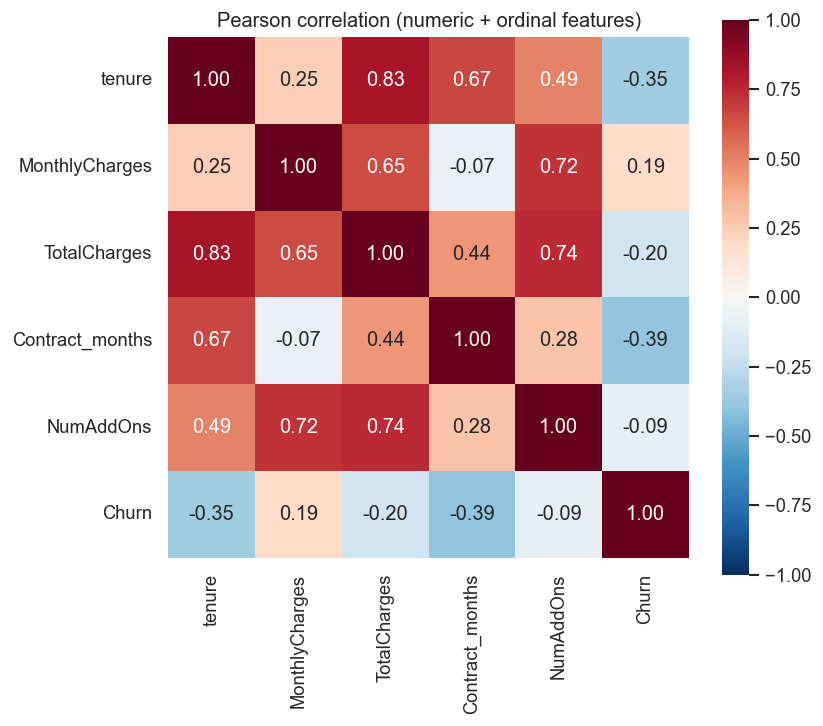

corr(TotalCharges, tenure × MonthlyCharges) = 0.9996


In [20]:
display(Image(str(config.FIGURES_DIR / "eda_correlation_heatmap.png")))
print("corr(TotalCharges, tenure × MonthlyCharges) =",
      round(np.corrcoef(df["TotalCharges"], df["tenure"] * df["MonthlyCharges"])[0, 1], 4))

**Interpretation:** `TotalCharges` is almost exactly `tenure × MonthlyCharges` (r ≈ 0.9996), so it is
largely redundant. `tenure` (r ≈ −0.35) and contract length (r ≈ −0.39) are most negatively correlated with
churn. Pearson correlation on one-hot/ordinal codes is only a rough guide; the chi-square table above is
the more appropriate test for categorical variables. The effect of keeping or dropping `TotalCharges` is
tested with cross-validation in notebook 02.

## Save the cleaned dataset and regenerate the EDA figures

In [21]:
from src.data_preprocessing import save_processed
from src.eda import run_eda
save_processed(clean_data(raw))
summary = run_eda()
print("Saved:", config.PROCESSED_DATA_PATH.relative_to(config.PROJECT_ROOT))
print("Figures:", sorted(p.name for p in config.FIGURES_DIR.glob("eda_*.png")))

Saved: data/processed/telco_churn_clean.csv
Figures: ['eda_boxplots.png', 'eda_churn_by_contract.png', 'eda_churn_by_monthly_band.png', 'eda_churn_by_payment.png', 'eda_churn_by_tenure_group.png', 'eda_churn_distribution.png', 'eda_correlation_heatmap.png', 'eda_numeric_histograms.png', 'eda_scatter_tenure_monthly.png', 'eda_service_features.png', 'eda_tenure_contract_heatmap.png']


## Summary of EDA findings
1. 26.5 % churn → imbalanced target; accuracy alone is misleading.
2. Strongest associations: contract type, tenure, internet service type, payment method, and
   having online security / tech support.
3. No IQR outliers; `TotalCharges` blanks were new customers and were set to 0.
4. `customerID` is an identifier and is excluded from modelling.
5. `gender` and `PhoneService` show no significant association with churn.